# W09A Formulating simple loss functions

In [5]:
import torch
import numpy as np
import matplotlib.pyplot as plt

### Linear Fit

tensor([1., 1., 1., 1., 1., 1., 1., 1.], grad_fn=<AddBackward0>)
Step 0, Loss: 11.171249389648438
Step 1000, Loss: 0.22658193111419678
Step 2000, Loss: 0.22652524709701538
Step 3000, Loss: 0.22652529180049896
Step 4000, Loss: 0.22652526199817657


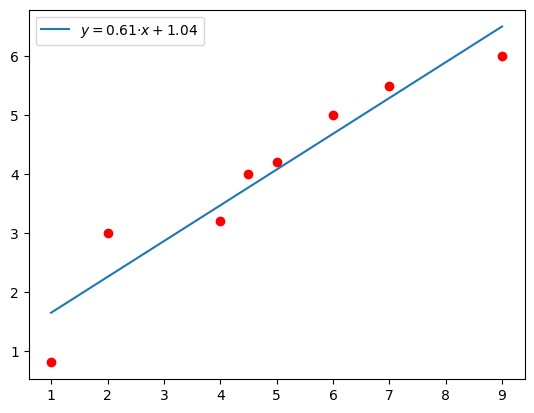

In [16]:
xs = torch.tensor([1., 2, 4, 4.5, 5, 6, 7, 9])
ys = torch.tensor([0.8, 3, 3.2, 4, 4.2, 5, 5.5, 6])

class Line(torch.nn.Module):
    def __init__(self, w=0, b=1):
        super().__init__()
        self.w = torch.nn.Parameter(torch.tensor(float(w)))
        self.b = torch.nn.Parameter(torch.tensor(float(b)))
        # converting into parameter type to tell the module
        # that we want gradients

    def forward(self, x):
        y = self.w * x + self.b
        return y

line = Line()
# with w=0, b=1, line(xs) should be a tensor of 1's
print(line(xs))

# now we can define a loss function to optimize with our Line class:
optimizer = torch.optim.Adam(line.parameters(), lr=0.01)
steps = 5000
for step in range(steps):
    optimizer.zero_grad() # wipe the previous calculated gradients
    ys_model = line(xs)
    loss = torch.mean((ys_model - ys)**2)
    loss.backward()
    optimizer.step()
    if step % 1000 == 0:
        print(f'Step {step}, Loss: {loss.item ()}')

fig, ax = plt.subplots()

ax.scatter(xs, ys, c='r')
with torch.no_grad():
    ax.plot(xs, line(xs), label=r'$y=$'+f'{line.w.item():.2f}'+r'$\cdot x+$'+f'{line.b.item():.2f}')
ax.legend()


### Center of mass in 1D

In [ ]:
class CM(torch.nn.Module):
    def __init__(self, cm =1):
        super().__init__ ()
        self.cm = torch.nn. Parameter (torch.tensor(float(cm)))
    def forward(self, x):
        distances = x - self.cm
        return distances

xs = torch.rand(10) * 2
xs -= torch.mean(xs)
xs += 5  # mean of 5

cm = CM()
optimizer = torch.optim.Adam(cm.parameters(), lr =0.01)
steps = 2000
for step in range(steps):
    optimizer.zero_grad() # wipe the previous calculated gradients
    ds = cm(xs)
    loss = torch.mean(ds**2)
    loss.backward()
    optimizer.step()
    if step % 200 == 0:
        print(f'Step {step}, Loss: {loss.item ()}')

# printing "all" named parameters in 'cm'
for name , parameter in cm.named_parameters():
    print(name, ':', parameter.data)
# center of mass should be 5 (the mean)

Step 0, Loss: 16.361553192138672
Step 200, Loss: 5.32202672958374
Step 400, Loss: 1.4286903142929077
Step 600, Loss: 0.5084120035171509
Step 800, Loss: 0.37382036447525024
Step 1000, Loss: 0.36215463280677795
Step 1200, Loss: 0.3615698218345642
Step 1400, Loss: 0.3615533709526062
Step 1600, Loss: 0.3615531623363495
Step 1800, Loss: 0.36155322194099426
cm : tensor(5.0000)


### Roots of function

In [39]:
class FZero(torch.nn.Module):
    '''
    given f(x), find x0 such that f(x0)=0
    i.e find the root of the function
    '''
    def __init__(self, f, x0=0):
        super().__init__()
        self.f = f
        self.x0 = torch.nn. Parameter(torch.tensor(float(x0)))
    def forward(self):
        return self.f(self.x0)

# the function for which we seek the nodes
f = lambda x: (x -8) *(x+2)
# instantiation
fzero = FZero(f)
# f(x0) according to the forward-method with x0=0 should be -16
print(fzero())

optimizer = torch.optim.Adam(fzero.parameters(), lr =0.01)

steps = 2000
for step in range(steps):
    optimizer.zero_grad() # wipe the previous calculated gradients
    loss = fzero()**2
    loss.backward()
    optimizer.step()
    if step % 200 == 0:
        print(f'Step {step}, Loss: {loss.item ()}')

# check the root is correct
root = fzero.x0.item()
print(f'f(x0)={f(root):.4f}')

tensor(-16., grad_fn=<MulBackward0>)
Step 0, Loss: 256.0
Step 200, Loss: 10.921854972839355
Step 400, Loss: 0.003035914385691285
Step 600, Loss: 3.139174031829839e-09
Step 800, Loss: 9.094945629950502e-11
Step 1000, Loss: 9.094945629950502e-11
Step 1200, Loss: 9.094945629950502e-11
Step 1400, Loss: 9.094945629950502e-11
Step 1600, Loss: 9.094945629950502e-11
Step 1800, Loss: 6.963317422670201e-11
f(x0)=-0.0000


# W09B The gradient and a first steepest descent

In [40]:
import torch
import numpy as np
import matplotlib.pyplot as plt

[Text(0.5, 0, '$x_1$'), Text(0, 0.5, '$x_2$')]

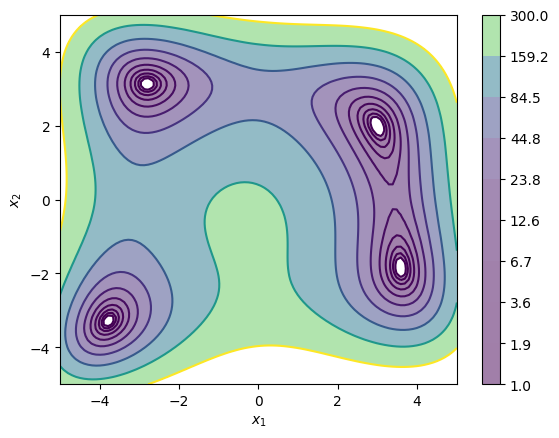

In [43]:
f = lambda x1, x2 : (x1**2 + x2 -11)**2 + (x1 + x2**2 - 7)**2

vals = np.linspace(-5,5,100)
x1d, x2d = np.meshgrid(vals ,vals)
yd = f(x1d, x2d)

fig, ax = plt.subplots()
levels = np.logspace(0, np.log10(300), 10)
ax.contour(x1d, x2d, yd, levels=levels)
color_map = ax.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
fig.colorbar(color_map, ax=ax)
ax.set(xlabel='$x_1$', ylabel='$x_2$')

### The gradients

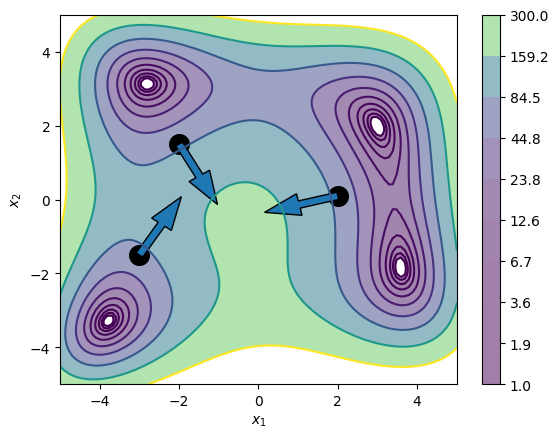

In [49]:
f = lambda x1, x2 : (x1**2 + x2 -11)**2 + (x1 + x2**2 - 7)**2

vals = np.linspace(-5,5,100)
x1d, x2d = np.meshgrid(vals ,vals)
yd = f(x1d, x2d)

fig, ax = plt.subplots()
levels = np.logspace(0, np.log10(300), 10)
ax.contour(x1d, x2d, yd, levels=levels)
color_map = ax.contourf(x1d, x2d, yd, levels=levels, alpha=0.5)
fig.colorbar(color_map, ax=ax)
ax.set(xlabel='$x_1$', ylabel='$x_2$')


### ADDING GRADIENTS HERE ###
for P0 in[[-2, 1.5], [2, .1], [-3, -1.5]]:
    P0 = torch.tensor(P0, requires_grad=True)
    y = f(*P0)  # forward pass
    y.backward() # backward pass
    grad_of_y = P0.grad  # get gradient
    P0 = P0.detach()
    v = grad_of_y /np.linalg.norm(grad_of_y)
    ax.scatter(*P0,s=200,c='k')
    ax.arrow(*P0,*v,width =0.2)


### Optimizing manually: Steepest descent